In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np
import torch

import matplotlib.pyplot as plt
from torchvision import datasets, transforms

In [19]:
# Definir una transformación para normalizar los datos
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Descargar y cargar los datos de entrenamiento
trainset = datasets.MNIST(
    'MNIST_data/',
    download=True,
    train=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True
)

# Descargar y cargar los datos de prueba
testset = datasets.MNIST(
    'MNIST_data/',
    download=True,
    train=False,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=True
)

In [20]:
dataiter = iter(trainloader)
images, labels = next(dataiter)

images.shape

torch.Size([64, 1, 28, 28])

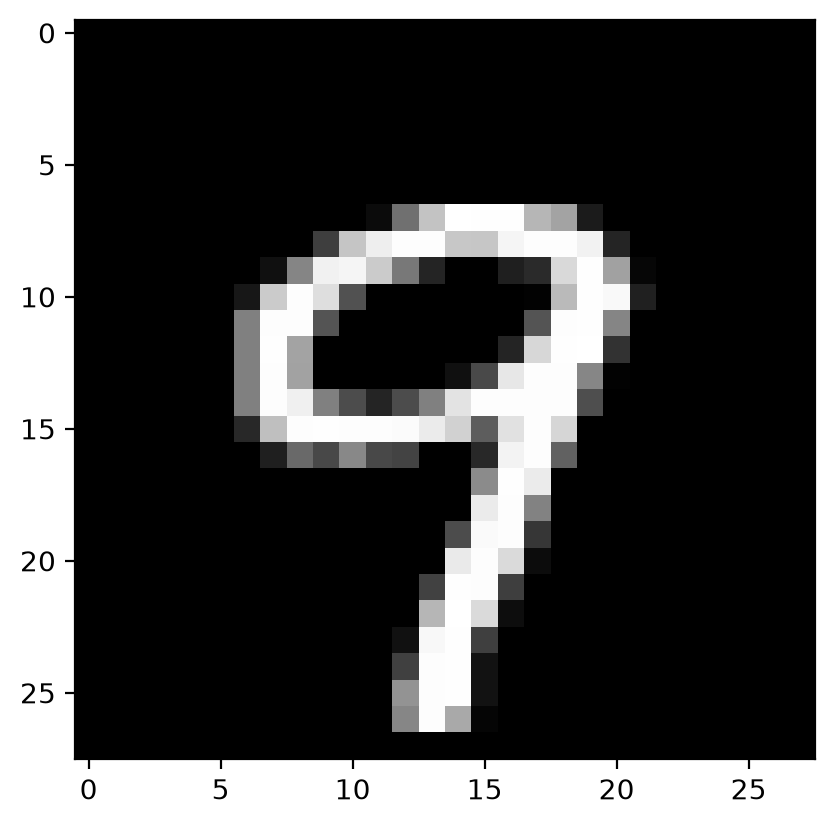

In [21]:
plt.imshow(images[0].numpy().squeeze(), cmap='gray')
plt.show()

In [22]:
labels[0]

tensor(9)

In [23]:
images = images.view(images.shape[0], -1)
images.shape

torch.Size([64, 784])

In [24]:
import torch.nn as nn

model = nn.Sequential(
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 10)
)

model

Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=10, bias=True)
)

In [25]:
logits = model(images)
logits.shape

torch.Size([64, 10])

In [26]:
logits[0]

tensor([-0.0016, -0.1659, -0.0927,  0.0693,  0.0595, -0.1292,  0.0548,  0.0335,
        -0.0812, -0.0727], grad_fn=<SelectBackward0>)

In [27]:
probabilities = torch.softmax(logits[0], dim=0)
probabilities

tensor([0.1028, 0.0872, 0.0939, 0.1104, 0.1093, 0.0905, 0.1088, 0.1065, 0.0949,
        0.0958], grad_fn=<SoftmaxBackward0>)

In [28]:
probabilities.argmax()

tensor(3)

In [29]:
criterion = nn.CrossEntropyLoss()

In [30]:
loss = criterion(logits, labels)
loss

tensor(2.2911, grad_fn=<NllLossBackward0>)

In [31]:
model[0].weight.shape

torch.Size([128, 784])

In [32]:
model[0].bias.shape

torch.Size([128])

In [33]:
total_params = sum(p.numel() for p in model.parameters())
total_params

109386

In [34]:
model[0].weight.requires_grad

True

In [35]:
for name, param in model.named_parameters():
    print(name, param.shape)

0.weight torch.Size([128, 784])
0.bias torch.Size([128])
2.weight torch.Size([64, 128])
2.bias torch.Size([64])
4.weight torch.Size([10, 64])
4.bias torch.Size([10])
